In [73]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv('cleaned_online_retail.csv', index_col=0)

abc = pd.read_csv('abc_table.csv')

In [74]:
abc.head()

,StockCode,Revenue,Revenue_%,Cumulative_%,Class
0,23843,168469.60,1.928497,1.928497,A
1,22423,142264.75,1.628526,3.557023,A
2,85123A,100547.45,1.150982,4.708005,A
3,85099B,85040.54,0.973472,5.681477,A
4,23166,81416.73,0.931990,6.613467,A


In [75]:
total_rev = abc['Revenue'].sum()
print(f"{total_rev:,.2f}")

8,735,797.80


In [76]:
abc_A = abc[abc['Class'] == 'A'].copy()

selected = abc_A[abc_A['Cumulative_%'] <= 50]

In [77]:
selected.head()

,StockCode,Revenue,Revenue_%,Cumulative_%,Class
0,23843,168469.60,1.928497,1.928497,A
1,22423,142264.75,1.628526,3.557023,A
2,85123A,100547.45,1.150982,4.708005,A
3,85099B,85040.54,0.973472,5.681477,A
4,23166,81416.73,0.931990,6.613467,A


In [78]:
selected.shape

(230, 5)

In [79]:
abc_A.shape # No. of Class A's SKUs

(783, 5)

*ABC analysis identified 783 Class A SKUs, contributing approximately 80% of total revenue. As revenue within Class A was distributed across many products rather than concentrated in a few domainat SKUs, the 50% Totol Revenue Threshold was adopted based on the Pareto principle.*


*Class A SKUs were ranked by revenue contribution and selected until their cumulative revenue reached approximately 50% of total revenue. This resulted in 231 selected SKUs, representing the most commercially significant products for subsequent demand modelling and inventory optimization.*



## Demand Modelling

In [80]:
selected_skus = selected['StockCode'].tolist()

In [81]:
demand_data = data[data['StockCode'].isin(selected_skus)]

In [82]:
demand_data.shape

(125101, 8)

*There are 159,002 transaction records from the selected 230 SKUs*

#### Weekly Demand Series

In [83]:
demand_data['InvoiceDate'].dtype # Datatype is object

<StringDtype(storage='python', na_value=nan)>

In [84]:
demand_data['InvoiceDate'] = pd.to_datetime(demand_data['InvoiceDate'])

In [85]:
demand_data['InvoiceDate'].dtype 

dtype('<M8[us]')

*dtype('<M8[ns]') is just NumPy's way of displaying: datetime64[ns]*

In [86]:
weekly_demand = (demand_data.groupby(['StockCode',pd.Grouper(key='InvoiceDate', freq='W')])['Quantity'].sum().reset_index())

In [87]:
weekly_demand

,StockCode,InvoiceDate,Quantity
0,15036,2010-12-05,72
1,15036,2010-12-12,12
2,15036,2010-12-19,24
3,15036,2010-12-26,24
4,15036,2011-01-09,12
...,...,...,...
10626,85152,2011-11-13,67
10627,85152,2011-11-20,1
10628,85152,2011-11-27,27
10629,85152,2011-12-04,484


### Exploratory Demand Analysis

*Analysing all 231 selected Class A SKUs individually would be impratical. Therefore, several high-revenue SKUs were first inspected to understand their weekly demand patterns and assess their suitability for demand forecasting. The highest-revenye SKU was selected as the first SKU for demand forecasting*


In [88]:
top_sku = selected.iloc[0]['StockCode']

sku_weekly = weekly_demand[weekly_demand['StockCode'] == top_sku]

In [89]:
top_sku = selected.iloc[0]['StockCode']

print(top_sku)

23843


In [90]:
len(sku_weekly)

1

*SKU 23843 (PAPER CRAFT, LITTLE BIRDIE) generated approximately £168k in revenue from a single transaction. Given its exceptionally high revenue contribution despite limited transaction activity, the SKU was selected for further investigation.*

In [91]:
weekly_demand.groupby('StockCode').size().describe()

count    230.000000
mean      46.221739
std        9.950465
min        1.000000
25%       42.250000
50%       52.000000
75%       53.000000
max       53.000000
dtype: float64

In [92]:
weekly_demand[ weekly_demand['StockCode'] == top_sku]

,StockCode,InvoiceDate,Quantity
8371,23843,2011-12-11,80995


In [93]:
print(type(top_sku))
print(top_sku)

<class 'str'>
23843


In [94]:
weekly_demand['StockCode'].dtype

<StringDtype(storage='python', na_value=nan)>

In [95]:
selected['StockCode'].dtype

<StringDtype(storage='python', na_value=nan)>

In [96]:
top_sku = selected.iloc[0]['StockCode']

print(top_sku)

23843


In [97]:
demand_data[demand_data['StockCode'] == top_sku]

,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
InvoiceNo,,,,,,,,
581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom,168469.6


*Although the transaction appears to be legitimate rather than a data error, the SKU lacks sufficient historical demand observations for meaningful forecasting.*

*This finding highlighted that high revenue does not necessarily imply sufficient demand history for reliable forecasting As a result, SKUs wre not selected soley based on revenue ranking. , first insghts is SKUs were not selected solely based on revenue ranking.*

In [98]:
sku_counts = (weekly_demand.groupby('StockCode').size().reset_index(name='weeks'))

sku_counts.head()

,StockCode,weeks
0,15036,52
1,15056BL,53
2,15056N,53
3,20679,53
4,20685,53


In [99]:
sku_counts['weeks'].describe()

count    230.000000
mean      46.221739
std        9.950465
min        1.000000
25%       42.250000
50%       52.000000
75%       53.000000
max       53.000000
Name: weeks, dtype: float64

- Median = 52 weeks (half of the selected SKUs have 52 weeks or more of demand history; since the dataset covers about one year, a typical SKU has demand data for almost the entire year)
- 75th percentile = 53 weeks (75% of SKUs have 53 weeks or fewer of demand history)
- Max = 53 weeks.

*This confirms that SKU 23843 is an outlier (Min = 1 week), as the vast majority of selected SKUs have almost a full year of weekly demand observations. It further confirms that revenue alone is insufficient for identifying suitable candidates for demand forecasting.*

#### Lowest-history Products

In [100]:
selected_with_weeks = selected.merge(sku_counts, on='StockCode', how='left')

In [101]:
selected_with_weeks[['StockCode', 'Revenue', 'weeks']].sort_values('weeks').head(20)

# Now you can see revenue (from selected) and demand history (from sku_count) together
# After merging, we can ask: which SKUs have 1. high revenue and 2. enough weekly observations
# And those become our forecasting candidates

,StockCode,Revenue,weeks
0,23843,168469.60,1
33,23355,24302.55,16
127,23356,12954.75,16
145,22867,12064.63,22
128,23313,12950.22,22
7,23084,51251.24,22
137,22866,12204.66,22
221,22632,8738.52,22
142,22941,12133.00,23
105,22114,15386.07,23


*SKU 23843 is not only an outlier in terms of weekly observations but there are several other SKUs with relatively short histories. So the issue is not limited to a single SKU*

In [102]:
# Qunatify the impact of differet cutoffs

print(">= 10 weeks:",
        (selected_with_weeks['weeks'] >= 10).sum())

print(">= 20 weeks:",
        (selected_with_weeks['weeks'] >= 20).sum())

# 10-week and 20-week threshold barely filters anything

print(">= 30 weeks:",
        (selected_with_weeks['weeks'] >= 30).sum()) # Removes 21 SKUs, This is the first threshold that meaningfully excludes products with limited history while retaining most SKUs

print(">= 40 weeks:",
        (selected_with_weeks['weeks'] >= 40).sum())

print(">= 50 weeks:",
        (selected_with_weeks['weeks'] >= 50).sum())




>= 10 weeks: 229
>= 20 weeks: 227
>= 30 weeks: 209
>= 40 weeks: 180
>= 50 weeks: 140


*The weekly observation count was used as an additional screening criterion when selecting forecastong candidates. Although most selected Class A SKUs exhibited nearly a full year of demand history, several high-revenue products contained fewer than 30 weekly observations.*


*To ensure sufficient historical information for demand distribution estimation, only SKUs with at least 30 weekly demand observations were retained for subsequent forcasting analysis. This threshold excluded 21 products with limited demand histories while retaining 209 of the 230 selected Class A SKUs.*

#### Final Modelling Set

In [103]:
forecast_skus = selected_with_weeks[selected_with_weeks['weeks'] >= 30].copy()

forecast_skus.shape

(209, 6)

In [104]:
forecast_skus.sort_values('Revenue', ascending=False).head(20) # Identify representative SKUs that is High rev + >= 30 weeks

,StockCode,Revenue,Revenue_%,Cumulative_%,Class,weeks
1,22423,142264.75,1.628526,3.557023,A,53
2,85123A,100547.45,1.150982,4.708005,A,53
3,85099B,85040.54,0.973472,5.681477,A,53
4,23166,81416.73,0.931990,6.613467,A,32
5,47566,68785.23,0.787395,7.400862,A,53
6,84879,56413.03,0.645768,8.046630,A,53
8,22502,47348.35,0.542004,9.175314,A,34
9,79321,46265.11,0.529604,9.704918,A,51
10,22086,42584.13,0.487467,10.192385,A,36
11,21137,39045.80,0.446963,10.639348,A,49


In [105]:
chosen_sku = forecast_skus.sort_values('Revenue', ascending=False).iloc[0]['StockCode']

# The highest-revenue SKU among those 219 SKUs that have at least 30 weeks of history

In [106]:
sku_weekly = weekly_demand[weekly_demand['StockCode'] == chosen_sku]

sku_weekly['Quantity'].describe()

count     53.000000
mean     233.471698
std      108.610915
min       72.000000
25%      149.000000
50%      214.000000
75%      300.000000
max      648.000000
Name: Quantity, dtype: float64

*The selected SKU (SKU 22423) contains 53 weekly demand observations, providing approximately one year of demand history for analysis. Average weekly demand was 233 units(If you randomly pick a week, demand is ard 233 units), while the median demand was 214 units(Half the weeks have demand below 214, hald the weeks have), indicating that demand is reasonable balanced without severe skewness.*


*Demand variability is evident, with a standard deviation of aproximately 109 units and a demand range between 72(min) and 648(max) units per week. These results suggest that demand uncertainity exists and inventory decisions based soley on average demand may lead to overstocking or stockout risks.*


*Therefore, the SKU appears suitable for demand forecasting and inventory optimization analysis/*

## EDA of a Forecasting Candidate SKU

### Time Series Plot

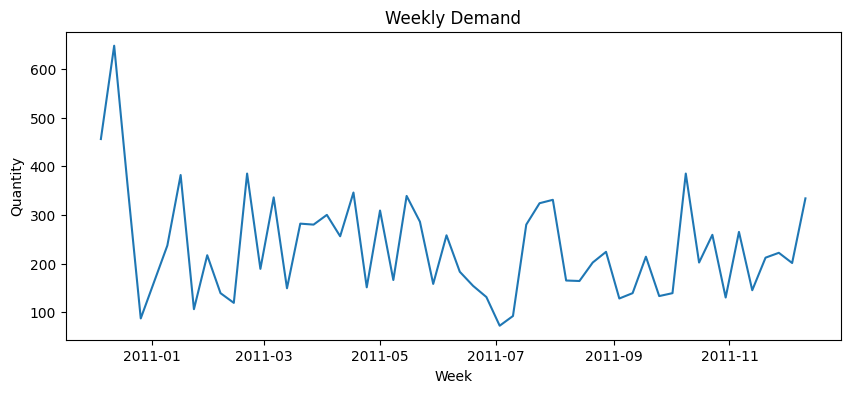

In [107]:
plt.figure(figsize=(10,4))

plt.plot(sku_weekly["InvoiceDate"],sku_weekly["Quantity"])

plt.title("Weekly Demand")
plt.xlabel("Week")
plt.ylabel("Quantity")
plt.show()

#### Weekly Demand Pattern

*The weekly demand of SKU 22423 fluctuates substantially throughout the year, with demand ranging from approximately 70 to 650 units. Several sharp peaks and troughs are observed, indicating considerable week-to-week variation.*

*Despite these fluctuations, no clear long-term upward or downward trend is evident. Demand appears to fluctuate around a similar level over time, suggesting that the underlying demand pattern remains relatively consistent while still exhibiting substantial variability.*

*This supports the use of demand distribution analysis for subsequent inventory optimization.*

### Histogram

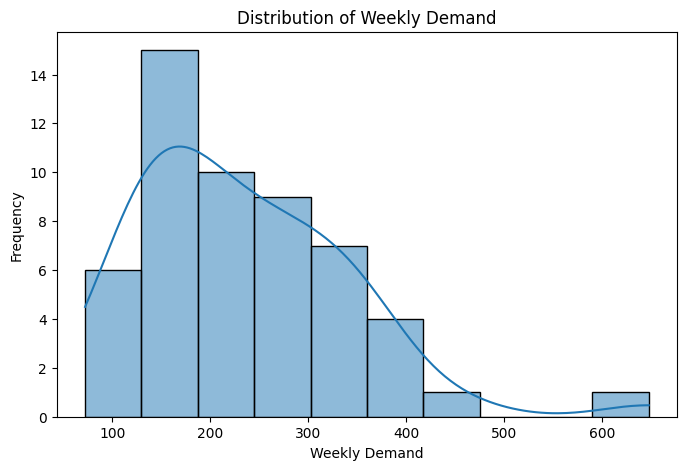

In [108]:
plt.figure(figsize=(8,5))

sns.histplot(sku_weekly["Quantity"],bins=10,kde=True)

plt.title("Distribution of Weekly Demand")
plt.xlabel("Weekly Demand")
plt.ylabel("Frequency")

plt.show()

#### Demand Distribution
*The histogram shows that most weekly demand observations are concentrated between approximately 120 and 350 units, with the highest frequency occurring around 150 to 250 units.*

*A small number of weeks exhibit substantially higher demand, including an extreme observation above 600 units. This creates a right-skewed distribution and highlights the presence of demand uncertainty.*

*The time series plot confirms that demand fluctuates around a similar level without a clear long-term trend. However, the histogram provides a more useful representation for inventory optimization because it reveals the overall distribution of demand values. Therefore, the histogram is used to estimate demand characteristics required for the Newsvendor model.*